# 05 -- Train

`qwenmoe/train/` owns the training-loop lifecycle (`Trainer`: AdamW +
warmup/cosine schedule, checkpoint save/resume, JSON-lines logging),
scaling-law planning utilities (`scaling.py`), and the research-style
comparison framework (`compare.py`) that trains several named config
variants on one identical fixed token slice.

*Part of the [training-my-moe code tour](00_overview.ipynb) -- see also: [config](01_config.ipynb) - [tokenizer](02_tokenizer.ipynb) - [data](03_data.ipynb) - [model](04_model.ipynb) - [train](05_train.ipynb) - [viz](06_viz.ipynb).*

In [1]:
from pathlib import Path
import os

# Walk up until we find pyproject.toml, so these cells work no matter where Jupyter's cwd starts.
repo_root = Path.cwd()
while not (repo_root / "pyproject.toml").exists():
    repo_root = repo_root.parent
os.chdir(repo_root)
print("Working directory:", Path.cwd())

import dataclasses
import json
import tempfile

import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from qwenmoe.config import ModelConfig, TrainConfig, DataConfig
from qwenmoe.model.transformer import QwenMoEModel
from configs.presets import SMOKE_TEST, BASELINE

Working directory: /Users/sjoseph/Documents/Study/training-my-moe


Matplotlib is building the font cache; this may take a moment.


## Training-loop primitives (`trainer.py`)

### `select_device`

In [2]:
from qwenmoe.train.trainer import select_device

for requested in ["cpu", "auto", "mps"]:
    print(requested, "->", select_device(requested))

cpu -> cpu
auto -> mps
mps -> mps


### `lr_multiplier` -- linear warmup + cosine decay

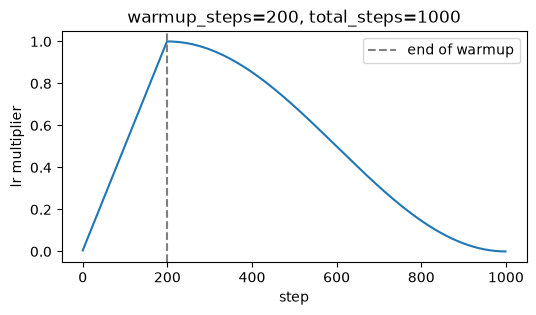

multiplier at step 0:         0.005
multiplier at end of warmup:  1.0
multiplier at the very end:   3.8553092647219955e-06


In [3]:
from qwenmoe.train.trainer import lr_multiplier

warmup_steps, total_steps = 200, 1000
mults = [lr_multiplier(s, warmup_steps, total_steps) for s in range(total_steps)]

plt.figure(figsize=(6, 3))
plt.plot(mults)
plt.axvline(warmup_steps, color="gray", linestyle="--", label="end of warmup")
plt.xlabel("step"); plt.ylabel("lr multiplier")
plt.title("warmup_steps=200, total_steps=1000"); plt.legend()
plt.show()

print("multiplier at step 0:        ", mults[0])
print("multiplier at end of warmup: ", mults[warmup_steps - 1])
print("multiplier at the very end:  ", mults[-1])

### `save_checkpoint` / `load_checkpoint`

In [4]:
from pathlib import Path
from qwenmoe.train.trainer import save_checkpoint, load_checkpoint

tiny_model_config = ModelConfig(
    vocab_size=20, d_model=16, n_layers=1, n_heads=2, n_kv_heads=1,
    d_ff=16, n_routed_experts=2, n_shared_experts=1, top_k=1, max_seq_len=8,
)
tiny_train_config = TrainConfig(batch_size=2, seq_len=4, total_tokens=100)
tiny_model = QwenMoEModel(tiny_model_config)
tiny_optimizer = torch.optim.AdamW(tiny_model.parameters(), lr=1e-3)

with tempfile.TemporaryDirectory() as tmp:
    ckpt_path = Path(tmp) / "demo.pt"
    save_checkpoint(
        ckpt_path, tiny_model, tiny_optimizer, tiny_model_config, tiny_train_config,
        step=42, tokenizer_meta={"tokenizer_type": "char", "tokenizer_path": "x"},
    )
    reloaded = load_checkpoint(ckpt_path)

print("reloaded step:               ", reloaded["step"])
print("reloaded model_config equal: ", reloaded["model_config"] == tiny_model_config)
print("state dict keys match:       ",
      set(reloaded["model_state_dict"].keys()) == set(tiny_model.state_dict().keys()))

reloaded step:                42
reloaded model_config equal:  True
state dict keys match:        True


### `Trainer.fit` -- a real (tiny) training run

In [5]:
from qwenmoe.train.trainer import Trainer
from qwenmoe.data.dataset import TokenDataset, train_val_split

all_tokens = torch.load(".cache/data/tiny_shakespeare_char/tokens.pt", weights_only=True)
train_tokens, val_tokens = train_val_split(all_tokens)

seq_len = 32
train_ds = TokenDataset(train_tokens, seq_len)
val_ds = TokenDataset(val_tokens, seq_len)

# lr/warmup deliberately tuned for a <50-step toy run (TrainConfig's real defaults assume
# hundreds+ of steps and would barely move the loss at all in just 20 steps).
demo_train_config = TrainConfig(
    batch_size=16, seq_len=seq_len, total_tokens=16 * seq_len * 20,  # 20 steps
    lr=1e-2, warmup_steps=5, eval_interval_steps=10, checkpoint_interval_steps=20,
    log_interval_steps=5, device="cpu",
)

demo_run_dir = tempfile.mkdtemp()
trainer = Trainer(
    demo_run_dir,
    tokenizer_meta={"tokenizer_type": "char", "tokenizer_path": ".cache/data/tiny_shakespeare_char/tokenizer.json"},
)

torch.manual_seed(0)
demo_model = QwenMoEModel(SMOKE_TEST)
result = trainer.fit(demo_model, train_ds, val_ds, demo_train_config)
print(result)

TrainResult(final_step=20, final_train_loss=3.1822540760040283, final_val_loss=3.1618122243881226, val_perplexity=23.61334986601609, log_path=PosixPath('/var/folders/c0/df5cjtmd3rq2_gflvgml65tr0000gn/T/tmp4vu_3v8f/logs/train.jsonl'), checkpoint_path=PosixPath('/var/folders/c0/df5cjtmd3rq2_gflvgml65tr0000gn/T/tmp4vu_3v8f/checkpoints/step_20.pt'))


### Resuming from a checkpoint

In [6]:
resumed_train_config = dataclasses.replace(demo_train_config, total_tokens=16 * seq_len * 30)  # 10 more steps
resumed_result = trainer.fit(demo_model, train_ds, val_ds, resumed_train_config, resume_from=result.checkpoint_path)
print("resumed and finished at step:", resumed_result.final_step, " (picked up from", result.final_step, ")")

resumed and finished at step: 30  (picked up from 20 )


### The real `runs/smoke_test` run's logged loss curve
A quick look needs no extra tooling -- just read the real JSON-lines log directly.

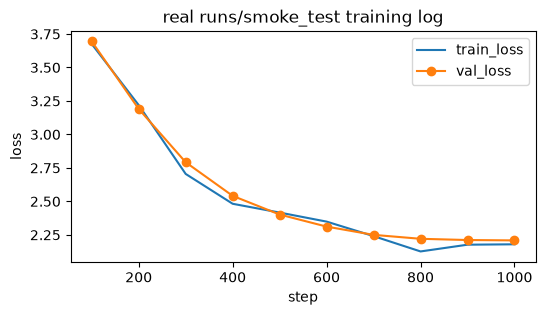

In [7]:
steps, train_losses = [], []
val_steps, val_losses = [], []
with open("runs/smoke_test/logs/train.jsonl") as f:
    for line in f:
        record = json.loads(line)
        if record["type"] == "step":
            steps.append(record["step"]); train_losses.append(record["train_loss"])
        elif record["type"] == "eval":
            val_steps.append(record["step"]); val_losses.append(record["val_loss"])

plt.figure(figsize=(6, 3))
plt.plot(steps, train_losses, label="train_loss")
plt.plot(val_steps, val_losses, marker="o", label="val_loss")
plt.xlabel("step"); plt.ylabel("loss"); plt.title("real runs/smoke_test training log"); plt.legend()
plt.show()

## Scaling-law utilities (`scaling.py`)

### `count_params`

In [8]:
from qwenmoe.train.scaling import count_params, chinchilla_budget, epochs_for_budget, calibrate_throughput

for name, cfg in [("SMOKE_TEST", SMOKE_TEST), ("BASELINE", BASELINE)]:
    torch.manual_seed(0)
    breakdown = count_params(QwenMoEModel(cfg))
    print(f"{name:10s} total={breakdown.total:>10,}  active={breakdown.active:>10,}  "
          f"({breakdown.active / breakdown.total:.1%} active per token)")

SMOKE_TEST total=   275,328  active=   177,024  (64.3% active per token)
BASELINE   total=23,477,504  active= 9,321,728  (39.7% active per token)


### `chinchilla_budget` / `epochs_for_budget`

In [9]:
active = count_params(QwenMoEModel(SMOKE_TEST)).active
budget = chinchilla_budget(active)
print(f"active params: {active:,}  chinchilla-style reference budget (~20x): {budget:,} tokens")

print()
print("epochs for a modest budget:", epochs_for_budget(total_tokens=2_000_000, unique_tokens=all_tokens.numel()))
print("epochs for a large budget (logs a >4-epoch warning -- check the cell's log output):",
      epochs_for_budget(total_tokens=10_000_000, unique_tokens=all_tokens.numel()))

training budget of 10000000 tokens over 1115394 unique tokens is 8.97 epochs (> 4) -- repeated-data returns diminish sharply past this point (Muennighoff et al., 2023)


active params: 177,024  chinchilla-style reference budget (~20x): 3,540,480 tokens

epochs for a modest budget: 1.7930883616013713
epochs for a large budget (logs a >4-epoch warning -- check the cell's log output): 8.965441808006856


### `calibrate_throughput` -- real measured tokens/sec

In [10]:
sample_x, sample_y = next(iter(DataLoader(train_ds, batch_size=16)))
tps = calibrate_throughput(QwenMoEModel(SMOKE_TEST), (sample_x, sample_y), device="cpu", n_steps=10)
print(f"measured throughput on this machine (cpu): {tps:,.0f} tokens/sec")

measured throughput on this machine (cpu): 49,006 tokens/sec


## Research-style comparison framework (`compare.py`)
Trains one `QwenMoEModel` per named variant on the identical fixed token
slice and identical token budget, so any difference in final metrics
reflects the architectural change, not different data or compute.

In [11]:
from qwenmoe.train.compare import run_comparison

compare_data_config = DataConfig(
    corpus="tiny_shakespeare", tokenizer_type="char", fixed_slice_tokens=20_000, fixed_slice_seed=0,
)
compare_train_config = TrainConfig(
    batch_size=16, seq_len=32, total_tokens=16 * 32 * 10,
    lr=1e-2, warmup_steps=3, eval_interval_steps=10, checkpoint_interval_steps=10,
    log_interval_steps=10, device="cpu",
)

compare_dir = tempfile.mkdtemp()
report = run_comparison(
    base_config=SMOKE_TEST,
    variants={"rope_baseline": {}, "nope_variant": {"positional_scheme": "nope"}},
    data_config=compare_data_config,
    train_config=compare_train_config,
    output_dir=compare_dir,
)
for name, variant_result in report.variants.items():
    print(f"{name:14s} final_val_loss={variant_result.final_val_loss:.4f}  "
          f"val_ppl={variant_result.val_perplexity:6.2f}  tok/s={variant_result.tokens_per_sec:,.0f}")

rope_baseline  final_val_loss=3.3509  val_ppl= 28.53  tok/s=53,080
nope_variant   final_val_loss=3.3483  val_ppl= 28.45  tok/s=54,940
